# LAB | Imbalanced

**Load the data**

In this challenge, we will be working with Credit Card Fraud dataset.

https://raw.githubusercontent.com/data-bootcamp-v4/data/main/card_transdata.csv

Metadata

- **distance_from_home:** the distance from home where the transaction happened.
- **distance_from_last_transaction:** the distance from last transaction happened.
- **ratio_to_median_purchase_price:** Ratio of purchased price transaction to median purchase price.
- **repeat_retailer:** Is the transaction happened from same retailer.
- **used_chip:** Is the transaction through chip (credit card).
- **used_pin_number:** Is the transaction happened by using PIN number.
- **online_order:** Is the transaction an online order.
- **fraud:** Is the transaction fraudulent. **0=legit** -  **1=fraud**


In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42

In [2]:
fraud = pd.read_csv("https://raw.githubusercontent.com/data-bootcamp-v4/data/main/card_transdata.csv")
fraud.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0.0
1,10.829943,0.175592,1.294219,1.0,0.0,0.0,0.0,0.0
2,5.091079,0.805153,0.427715,1.0,0.0,0.0,1.0,0.0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0.0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0.0


In [3]:
# Data quality checks before modelling
print(fraud.shape)
print(fraud.isna().sum().sum(), "missing values")
print(fraud.duplicated().sum(), "duplicated rows")
fraud.dtypes

(1000000, 8)
0 missing values


0 duplicated rows


distance_from_home                float64
distance_from_last_transaction    float64
ratio_to_median_purchase_price    float64
repeat_retailer                   float64
used_chip                         float64
used_pin_number                   float64
online_order                      float64
fraud                             float64
dtype: object

## 1. Distribution of the target variable

        count  percentage
fraud                    
0.0    912597       91.26
1.0     87403        8.74


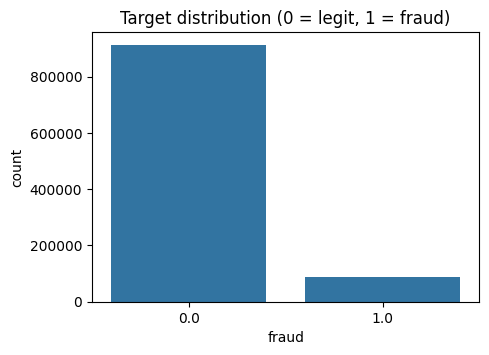

In [4]:
counts = fraud["fraud"].value_counts()
pct = fraud["fraud"].value_counts(normalize=True).mul(100).round(2)
print(pd.DataFrame({"count": counts, "percentage": pct}))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=fraud, x="fraud", ax=ax)
ax.set_title("Target distribution (0 = legit, 1 = fraud)")
plt.show()

**Answer:** yes, the dataset is clearly **imbalanced**. Fraudulent transactions are a small minority (~8.7%) versus ~91.3% legitimate ones (roughly 1 fraud for every 10 legit transactions). 

Consequence: a naive model predicting "legit" every time would reach ~91% accuracy while catching **zero** fraud. Accuracy is therefore a misleading metric here.

## Preparation: train/test split and scaling

Data-engineering best practices applied to avoid leakage:
- **Stratified split**, so train and test keep the same fraud ratio.
- The test set stays **untouched** (real-world distribution). Resampling is applied **only on the training set**.
- Scaling is **fitted on train only**, then applied to test (distances and ratios have very different scales).

In [5]:
X = fraud.drop(columns="fraud")
y = fraud["fraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print("Train:", X_train.shape, "| fraud rate:", round(y_train.mean() * 100, 2), "%")
print("Test :", X_test.shape, "| fraud rate:", round(y_test.mean() * 100, 2), "%")

Train: (800000, 7) | fraud rate: 8.74 %
Test : (200000, 7) | fraud rate: 8.74 %


## 2. & 3. Baseline: LogisticRegression and evaluation

**Choice of metric:** the cost of missing a fraud (false negative) is much higher than the cost of checking a legit transaction (false positive). We focus on the **minority class (fraud = 1)**:
- **Recall**: share of real frauds detected.
- **Precision**: share of fraud alerts that are real.
- **F1-score**: balance between the two.
- **PR-AUC (average precision)**: threshold-independent, robust to imbalance.

Accuracy is reported only for reference.

In [6]:
results = []

def evaluate(model, X_te, y_te, name):
    """Evaluate a fitted model on the (untouched) test set, focusing on the fraud class."""
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]

    print(f"===== {name} =====")
    print(classification_report(y_te, y_pred, digits=4))
    ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred), display_labels=["legit", "fraud"]).plot(cmap="Blues")
    plt.title(name)
    plt.show()

    results.append({
        "approach": name,
        "accuracy": (y_pred == y_te).mean(),
        "precision (fraud)": precision_score(y_te, y_pred),
        "recall (fraud)": recall_score(y_te, y_pred),
        "f1 (fraud)": f1_score(y_te, y_pred),
        "ROC-AUC": roc_auc_score(y_te, y_proba),
        "PR-AUC": average_precision_score(y_te, y_proba),
    })

===== Baseline (imbalanced) =====
              precision    recall  f1-score   support

         0.0     0.9634    0.9933    0.9781    182519
         1.0     0.8964    0.6056    0.7228     17481

    accuracy                         0.9594    200000
   macro avg     0.9299    0.7994    0.8505    200000
weighted avg     0.9575    0.9594    0.9558    200000



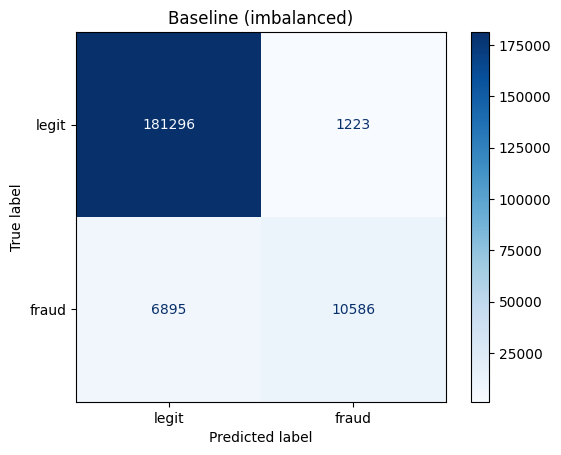

In [7]:
# Baseline: imbalanced data
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)
evaluate(log_reg, X_test_scaled, y_test, "Baseline (imbalanced)")

**Reading:** accuracy is high ( about 96%) but the key figure is the **recall on the fraud class:  about 61%**, i.e. about 4 frauds out of 10 are missed. Precision is high ( about 90%), so the baseline is conservative: few false alarms, but many undetected frauds. Let's see if rebalancing helps.

## 4. Oversampling (RandomOverSampler)

The minority class is duplicated at random in the **training set only** until both classes have the same size.

fraud
0.0    730078
1.0    730078
Name: count, dtype: int64


===== Oversampling =====
              precision    recall  f1-score   support

         0.0     0.9947    0.9335    0.9631    182519
         1.0     0.5774    0.9479    0.7176     17481

    accuracy                         0.9348    200000
   macro avg     0.7860    0.9407    0.8404    200000
weighted avg     0.9582    0.9348    0.9417    200000



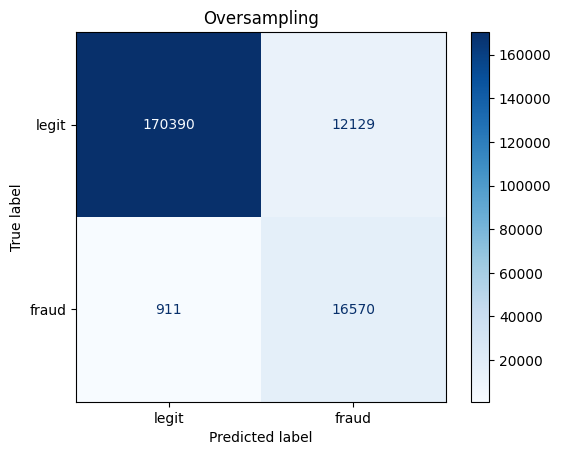

In [8]:
ros = RandomOverSampler(random_state=RANDOM_STATE)
X_train_over, y_train_over = ros.fit_resample(X_train_scaled, y_train)
print(y_train_over.value_counts())

log_reg_over = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg_over.fit(X_train_over, y_train_over)
evaluate(log_reg_over, X_test_scaled, y_test, "Oversampling")

## 5. Undersampling (RandomUnderSampler)

The majority class is randomly reduced in the **training set only** to match the minority class.

fraud
0.0    69922
1.0    69922
Name: count, dtype: int64
===== Undersampling =====
              precision    recall  f1-score   support

         0.0     0.9946    0.9336    0.9631    182519
         1.0     0.5773    0.9475    0.7175     17481

    accuracy                         0.9348    200000
   macro avg     0.7860    0.9405    0.8403    200000
weighted avg     0.9582    0.9348    0.9417    200000



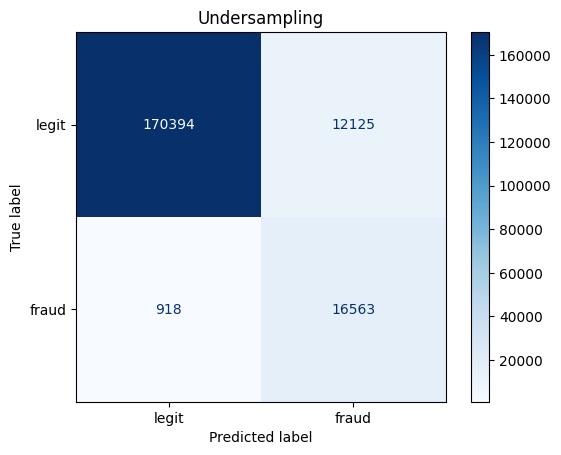

In [9]:
rus = RandomUnderSampler(random_state=RANDOM_STATE)
X_train_under, y_train_under = rus.fit_resample(X_train_scaled, y_train)
print(y_train_under.value_counts())

log_reg_under = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg_under.fit(X_train_under, y_train_under)
evaluate(log_reg_under, X_test_scaled, y_test, "Undersampling")

## 6. SMOTE

SMOTE creates **synthetic** minority samples by interpolating between neighbouring fraud observations (instead of duplicating them), again on the **training set only**.

fraud
0.0    730078
1.0    730078
Name: count, dtype: int64


===== SMOTE =====
              precision    recall  f1-score   support

         0.0     0.9947    0.9335    0.9631    182519
         1.0     0.5774    0.9481    0.7177     17481

    accuracy                         0.9348    200000
   macro avg     0.7860    0.9408    0.8404    200000
weighted avg     0.9582    0.9348    0.9417    200000



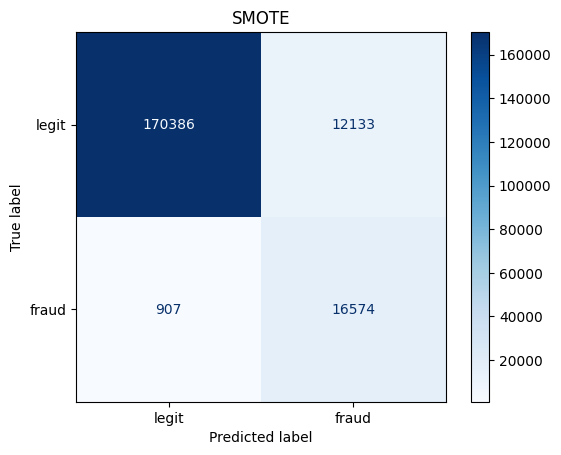

In [10]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)
print(y_train_smote.value_counts())

log_reg_smote = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg_smote.fit(X_train_smote, y_train_smote)
evaluate(log_reg_smote, X_test_scaled, y_test, "SMOTE")

## Comparison of the four approaches

In [11]:
summary = pd.DataFrame(results).set_index("approach").round(4)
summary

,accuracy,precision (fraud),recall (fraud),f1 (fraud),ROC-AUC,PR-AUC
approach,,,,,,
Baseline (imbalanced),0.9594,0.8964,0.6056,0.7228,0.9670,0.8072
Oversampling,0.9348,0.5774,0.9479,0.7176,0.9795,0.7574
Undersampling,0.9348,0.5773,0.9475,0.7175,0.9796,0.7569
SMOTE,0.9348,0.5774,0.9481,0.7177,0.9795,0.7574


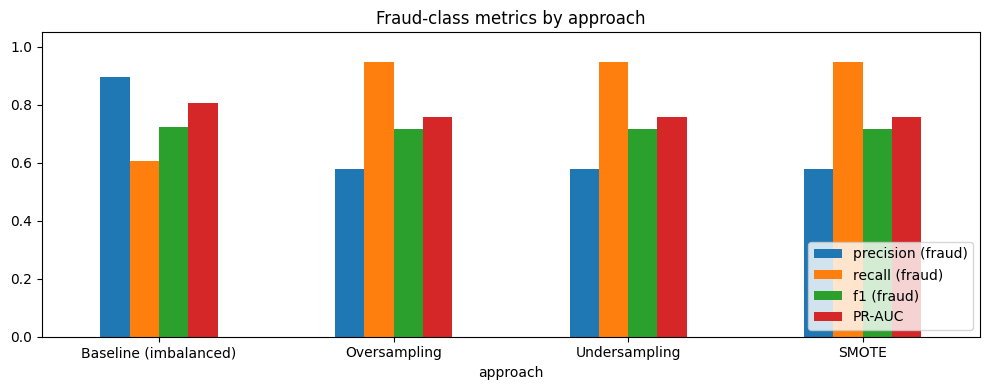

In [12]:
summary[["precision (fraud)", "recall (fraud)", "f1 (fraud)", "PR-AUC"]].plot(
    kind="bar", figsize=(10, 4), rot=0)
plt.title("Fraud-class metrics by approach")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Conclusions

| Approach | Precision (fraud) | Recall (fraud) | F1 (fraud) | PR-AUC |
|---|---|---|---|---|
| Baseline | 0.896 | 0.606 | 0.723 | 0.807 |
| Oversampling | 0.577 | 0.948 | 0.718 | 0.757 |
| Undersampling | 0.577 | 0.948 | 0.718 | 0.757 |
| SMOTE | 0.577 | 0.948 | 0.718 | 0.757 |

**Does balancing improve the model?** It depends on the business objective:

- **Recall jumps from ~61% to ~95%** with all three techniques: the model now catches almost every fraud. This is the main benefit when missing a fraud is the costly error.
- **The price is precision**, which falls from ~90% to ~58%: more legitimate transactions are flagged (more manual checks, more customer friction). Overall accuracy drops (96% to 93%), which is expected and not a sign of a worse model on this problem.
- **F1 and PR-AUC are essentially unchanged or slightly lower**, and ROC-AUC rises only marginally (0.967 to 0.980). Rebalancing mostly **shifts the decision threshold** of the logistic regression rather than making the model learn better patterns.
- **The three techniques give practically identical results.** Logistic regression is a simple, low-capacity model with few features, so duplicating (oversampling), reducing (undersampling) or synthesizing (SMOTE) samples has the same effect on its decision boundary.

**Engineering recommendations**
1. If recall on fraud is the priority, use any of the balanced approaches; **undersampling is the cheapest** (about 140k training rows instead of 1.46M, same performance), which matters for compute and pipeline run-time.
2. Alternatives to test: `class_weight="balanced"` (no resampling needed) or **tuning the probability threshold** on the baseline model, guided by the precision-recall curve and the real cost of a false positive vs a false negative.
3. Always resample **after** the train/test split and evaluate on the untouched test set, otherwise results are over-optimistic (data leakage).
4. Try a non-linear model (Random Forest, XGBoost) where resampling strategies may differ more.
